## Bus routing -  Gurobi Optimization

### Import Packages

In [1]:
import gurobipy as gp
from gurobipy import GRB
import random
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np

### Inputs
-Import data of bus stop locations 
-Initialise constant parameters
-calculate distance between bus stops

In [3]:
#Generate Data Inputs

# Select random seed
random.seed(1)

#coordinates of bus stops
data=pd.read_csv('data/tampines_busstoploc.csv')
stops = data['Number'].tolist()
n = len(stops)  # Now n is the length of the 'stops' list
print(stops)
print(data)

# Convert lat/lon into approximate Cartesian coordinates
coord_x = data['Longitude'].to_numpy()
coord_y = data['Latitude'].to_numpy()

# Compute distance matrix
distancelct = np.empty([n, n])
for i in range(n):
    for j in range(n):
        distancelct[i, j] = math.sqrt((coord_x[i] - coord_x[j])**2 + (coord_y[i] - coord_y[j])**2)
distancelct[np.diag_indices_from(distancelct)] = 99999  # no self loops
print(distancelct)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79]
    Number  BUS_STOP_N                  LOC_DESC  Latitude   Longitude
0        0       75009              TAMPINES INT  1.354802  103.943644
1        1       96081      GRACE INDEPENDENT CH  1.336535  103.955556
2        2       75201                   BLK 835  1.350810  103.933546
3        3       76319  TAMPINES EAST STN EXIT D  1.357657  103.955586
4        4       96391    AFT CHANGI BIZ PK CRES  1.336925  103.967817
..     ...         ...                       ...       ...         ...
75      75       96229               S'PORE EXPO  1.331236  103.958028
76      76       76369                  BLK 496F  1.360271  103.950264
77      77       76171                   BLK 266  

### Generate which stops are Origin, which are destination and which is both

In [4]:
# Initialize dictionary for roles
stop_roles = {}

# Assign fixed roles to first and last stops
stop_roles[stops[0]] = 'O'       # First stop is always Origin
stop_roles[stops[-1]] = 'D'      # Last stop is always Destination

# Assign random roles to intermediate stops
for stop in stops[1:-1]:
    stop_roles[stop] = random.choices(['O', 'D', 'OD'], weights=[0.4, 0.4, 0.2])[0]

print(stop_roles)

{0: 'O', 79: 'D', 1: 'O', 2: 'OD', 3: 'D', 4: 'O', 5: 'D', 6: 'D', 7: 'D', 8: 'D', 9: 'O', 10: 'O', 11: 'OD', 12: 'D', 13: 'D', 14: 'O', 15: 'D', 16: 'D', 17: 'O', 18: 'OD', 19: 'OD', 20: 'O', 21: 'O', 22: 'D', 23: 'OD', 24: 'O', 25: 'O', 26: 'D', 27: 'O', 28: 'O', 29: 'D', 30: 'D', 31: 'O', 32: 'O', 33: 'O', 34: 'D', 35: 'O', 36: 'O', 37: 'OD', 38: 'D', 39: 'D', 40: 'O', 41: 'OD', 42: 'OD', 43: 'O', 44: 'O', 45: 'D', 46: 'D', 47: 'OD', 48: 'D', 49: 'OD', 50: 'D', 51: 'O', 52: 'D', 53: 'OD', 54: 'OD', 55: 'D', 56: 'D', 57: 'O', 58: 'O', 59: 'D', 60: 'D', 61: 'O', 62: 'D', 63: 'D', 64: 'D', 65: 'O', 66: 'D', 67: 'D', 68: 'D', 69: 'D', 70: 'O', 71: 'D', 72: 'O', 73: 'O', 74: 'D', 75: 'OD', 76: 'D', 77: 'O', 78: 'O'}


### Generate Passenger Trips

In [5]:
import random

# Initialize number of passengers
num_passengers = 200

# Define origins and destinations based on stop roles
origins = [i for i in stops if stop_roles[i] in ('O', 'OD')]  # Origin or OD stop
destinations = [i for i in stops if stop_roles[i] in ('D', 'OD')]  # Destination or OD stop

# Initialize trip_counts dictionary to count trips between origin and destination pairs
trip_counts = {}

# Generate trips for passengers (only one loop needed now)
for _ in range(num_passengers):
    o = random.choice(origins)
    d = random.choice(destinations)
    
    while d == o:  # Ensure origin and destination are not the same
        d = random.choice(destinations)
    
    # Update trip count for the OD pair
    if (o, d) in trip_counts:
        trip_counts[(o, d)] += 1
    else:
        trip_counts[(o, d)] = 1

# Create OD pairs from trip_counts (only those with non-zero trips)
OD_pairs = [pair for pair, count in trip_counts.items() if count > 0]

# Print for debugging
print("Trip Counts:", trip_counts)
print("OD Pairs:", OD_pairs)


Trip Counts: {(53, 23): 1, (0, 19): 1, (57, 59): 1, (24, 46): 1, (53, 41): 1, (61, 41): 1, (47, 30): 1, (77, 59): 1, (70, 75): 1, (0, 45): 1, (53, 13): 1, (54, 59): 1, (23, 48): 1, (4, 52): 1, (37, 60): 1, (58, 19): 1, (53, 47): 1, (51, 41): 1, (42, 41): 1, (0, 56): 1, (57, 64): 2, (72, 39): 1, (47, 63): 1, (1, 23): 2, (73, 18): 1, (58, 62): 1, (20, 8): 1, (58, 29): 1, (2, 69): 1, (9, 8): 1, (1, 49): 1, (0, 79): 1, (28, 26): 1, (28, 12): 1, (72, 18): 1, (36, 34): 1, (9, 16): 1, (19, 29): 1, (54, 16): 1, (77, 30): 1, (75, 74): 1, (31, 50): 1, (33, 53): 1, (49, 12): 1, (1, 37): 1, (40, 39): 1, (42, 19): 1, (27, 11): 1, (27, 75): 1, (53, 22): 1, (70, 48): 1, (1, 46): 1, (18, 5): 1, (19, 49): 1, (53, 69): 1, (43, 56): 1, (24, 66): 1, (54, 49): 1, (24, 55): 1, (75, 3): 1, (41, 69): 1, (61, 38): 1, (77, 66): 1, (43, 6): 1, (32, 13): 1, (23, 6): 1, (32, 7): 1, (9, 37): 1, (32, 76): 1, (19, 47): 1, (61, 29): 1, (17, 2): 1, (58, 5): 1, (65, 22): 1, (61, 50): 1, (19, 74): 1, (72, 54): 1, (2, 45)

### Plot bus stop locations

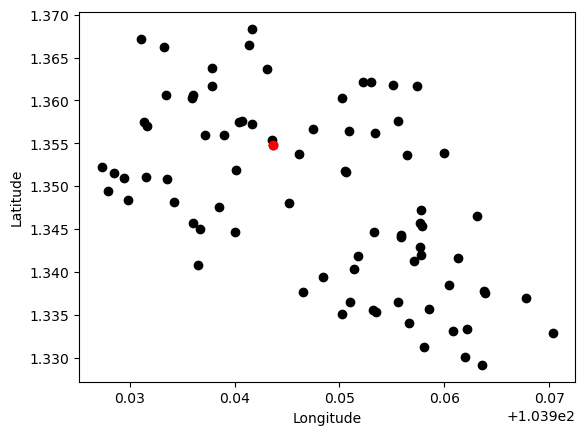

In [6]:
plt.plot(coord_x, coord_y, 'o', color='black')
plt.xlabel("Longitude")
plt.ylabel("Latitude");

#Tampines stop
tampines_coord_x = data.loc[data['BUS_STOP_N'] == 75009, 'Longitude'].to_numpy()
tampines_coord_y = data.loc[data['BUS_STOP_N'] == 75009, 'Latitude'].to_numpy()
plt.plot(tampines_coord_x, tampines_coord_y, 'o', color='red')

### Create model

In [7]:
# Create Model
model = gp.Model("TSP")


Set parameter Username
Set parameter LicenseID to value 2669003
Academic license - for non-commercial use only - expires 2026-05-21


### Decision Variables

In [8]:
# A[i,j] - 1 if city j is visited right after city i, 0 otherwise
A = model.addVars(stops, stops, vtype=GRB.BINARY, name="A")

# B[i,j] - 1 if city j is visited right after city i, 0 otherwise
B = model.addVars(stops, stops, vtype=GRB.BINARY, name="B")

# u[i] - auxiliary variable indicating tour ordering for bus A
uA = model.addVars(n, vtype=GRB.INTEGER, lb=0, ub=n-1, name="uA")

# u[i] - auxiliary variable indicating tour ordering for bus B
uB = model.addVars(n, vtype=GRB.INTEGER, lb=0, ub=n-1, name="uB")


### Objective Function

In [9]:
# Objective: Minimize total distance
model.setObjective(
    gp.quicksum(
        (
            A[stops[i], stops[j]] +  # Accessing A using stops[i] and stops[j]
            B[stops[i], stops[j]]    # Accessing B using stops[i] and stops[j]
        ) * distancelct[i, j]  # Using distancelct which is a NumPy array
        for i in range(n)
        for j in range(n) if i != j  # Avoid diagonal (self-loop) in the distance matrix
    ),
    GRB.MINIMIZE
)

### Constraints

In [10]:
# Starting at Tampines (index 0)
s = 0  # Tampines as the start index
t = 0 # Tampines as the end index (index 80)

# Start at Tampines (ensure one outgoing route from Tampines)
model.addConstr(gp.quicksum(A[stops[i], stops[j]] for j in range(n) if i != s) == 1)  # Outgoing route for Bus A
model.addConstr(gp.quicksum(B[stops[i], stops[j]] for j in range(n) if i != s) == 1)  # Outgoing route for Bus B
model.addConstr(uA[s] == 0)  # Set tour order for Bus A at Tampines (start)
model.addConstr(uB[s] == 0)  # Set tour order for Bus B at Tampines (start)

# End at Tampines (index 0)
model.addConstr(gp.quicksum(A[stops[j], stops[i]] for j in range(n) if j != t) == 1)  # Incoming route for Bus A
model.addConstr(gp.quicksum(B[stops[j], stops[i]] for j in range(n) if j != t) == 1)  # Incoming route for Bus B
model.addConstr(gp.quicksum(A[stops[i], stops[0]] for i in range(n) if i != 0) == 1)  # Bus A returns to stop 0
model.addConstr(gp.quicksum(B[stops[i], stops[0]] for i in range(n) if i != 0) == 1)  # Bus B returns to stop 0

<gurobi.Constr *Awaiting Model Update*>

In [11]:
# Define the sets of origin (O), destination (D), and origin-destination (OD) stops
# Define the sets of origin (O), destination (D), and origin-destination (OD) stops
origin_stops = set([i for i in stops if stop_roles[i] == 'O'])
destination_stops = set([i for i in stops if stop_roles[i] == 'D'])
od_stops = set([i for i in stops if stop_roles[i] == 'OD'])

# Ensure each origin and destination stop is visited exactly once (by either Bus A or Bus B)
for i in range(n):
    if (stops[i] in origin_stops or stops[i] in destination_stops) and i not in [s, t]:  # For O and D stops
        model.addConstr(
            gp.quicksum(A[stops[i], stops[j]] for j in range(n) if stops[j] != stops[i]) +  # Outgoing flow for Bus A
            gp.quicksum(B[stops[i], stops[j]] for j in range(n) if stops[j] != stops[i]) == 1  # Outgoing flow for Bus B
        )

# Ensure each origin-destination stop is visited once or twice (by either Bus A or Bus B)
for i in range(n):
    if stops[i] in od_stops and i not in [s, t]:  # For OD stops
        model.addConstr(
            gp.quicksum(A[stops[i], stops[j]] for j in range(n) if stops[j] != stops[i]) +  # Outgoing flow for Bus A
            gp.quicksum(B[stops[i], stops[j]] for j in range(n) if stops[j] != stops[i]) <= 2  # Outgoing flow for Bus B (once or twice)
        )

# Ensure each stop (except start and end) is visited at least once (incoming flow)
for i in range(n):
    if i not in [s, t]:  # Exclude the start and end stops
        model.addConstr(
            gp.quicksum(A[stops[j], stops[i]] for j in range(n) if stops[j] != stops[i]) +  # Incoming flow to stop i for Bus A
            gp.quicksum(B[stops[j], stops[i]] for j in range(n) if stops[j] != stops[i]) >= 1  # Incoming flow to stop i for Bus B (at least 1 visit)
        )


In [12]:
# Flow conservation for intermediate nodes (excluding start and end)
for i in range(n):
    if i != s and i != t:  # Exclude start (s) and end (t) stops
        # Flow conservation for Bus A
        model.addConstr(
            gp.quicksum(A[stops[i], stops[j]] for j in range(n) if j != i) ==  # Outgoing flow for Bus A
            gp.quicksum(A[stops[j], stops[i]] for j in range(n) if j != i)   )# Incoming flow for Bus A
        
        # Flow conservation for Bus B
        model.addConstr(
            gp.quicksum(B[stops[i], stops[j]] for j in range(n) if j != i) ==  # Outgoing flow for Bus B
            gp.quicksum(B[stops[j], stops[i]] for j in range(n) if j != i) )    # Incoming flow for Bus B

In [13]:
# Ensure each OD pair has a route
for (o, d) in OD_pairs:
    model.addConstr(
        gp.quicksum(A[stops[o], stops[j]] for j in range(n) if stops[j] != stops[o]) +  # Outgoing flow for Bus A from origin o
        gp.quicksum(B[stops[o], stops[j]] for j in range(n) if stops[j] != stops[o]) +  # Outgoing flow for Bus B from origin o
        gp.quicksum(A[stops[j], stops[d]] for j in range(n) if stops[j] != stops[d]) +  # Incoming flow for Bus A to destination d
        gp.quicksum(B[stops[j], stops[d]] for j in range(n) if stops[j] != stops[d]) >= 1  # Incoming flow for Bus B to destination d (at least 1 visit)
    )


In [14]:
# Subtour elimination constraints 
for i in range(n):
    for j in range(n):
        if i != j and i != 0 and j != 0:  # Exclude stop 0
            model.addConstr(uA[i] - uA[j] + 1 <= (n - 1) * (1 - A[i, j]))  # For Bus A
            model.addConstr(uB[i] - uB[j] + 1 <= (n - 1) * (1 - B[i, j]))  # For Bus B


### Solve Model

In [15]:
# Lists to store the time and objectives
times = []
obj_vals = []
bounds = []

def callback(model, where):
    if where == GRB.Callback.MIP:
        runtime = model.cbGet(GRB.Callback.RUNTIME)
        objbst = model.cbGet(GRB.Callback.MIP_OBJBST)
        objbnd = model.cbGet(GRB.Callback.MIP_OBJBND)
        
        # Only store finite values
        if objbst < GRB.INFINITY and objbnd < GRB.INFINITY:
            times.append(runtime)
            obj_vals.append(objbst)
            bounds.append(objbnd)

In [16]:
# Solve
# Set the computation time to be at most an hour
model.Params.TimeLimit = 3600  # in seconds
#model.setParam('MIPGap', 0.00001)  
model.optimize(callback)

Set parameter TimeLimit to value 3600
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i7-10510U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
TimeLimit  3600

Optimize a model with 12842 rows, 12960 columns and 148294 nonzeros
Model fingerprint: 0xb1a68ed6
Variable types: 0 continuous, 12960 integer (12800 binary)
Coefficient statistics:
  Matrix range     [1e+00, 8e+01]
  Objective range  [1e-04, 5e-02]
  Bounds range     [1e+00, 8e+01]
  RHS range        [1e+00, 8e+01]
Presolve removed 200 rows and 163 columns
Presolve time: 0.23s
Presolved: 12642 rows, 12797 columns, 86744 nonzeros
Variable types: 0 continuous, 12797 integer (12639 binary)

Root relaxation: objective 1.827413e-01, 364 iterations, 0.02 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj 

### Read output variables

In [17]:
# Initialize route for Bus A and Bus B
bus_a_route = [s]  # Start from stop 0
bus_b_route = [s]  # Start from stop 0

# Function to track route for a bus
def get_route(bus_route, decision_vars, current_stop):
    while True:
        # Find the next stop for the bus
        next_stop = None
        for j in range(n):
            if current_stop != j and decision_vars[current_stop, stops[j]].X > 0.5:  # If route [current_stop, j] is part of the optimal solution
                next_stop = stops[j]
                break

        if next_stop is None or next_stop == s:  # If no next stop is found, or the bus is back at stop 0
            break  # Stop when we reach stop 0 again

        bus_route.append(next_stop)  # Add the next stop to the route
        current_stop = next_stop  # Update the current stop
    
    bus_route.append(s)  # Enforce return to stop 0
    return bus_route

# Get the route for Bus A and Bus B
bus_a_route = get_route(bus_a_route, A, s)
bus_b_route = get_route(bus_b_route, B, s)

# Print the route for Bus A in order
print("Bus A route:")
for i in range(len(bus_a_route)-1):
    print(f"  {bus_a_route[i]} -> {bus_a_route[i+1]} (Order uA: {uA[bus_a_route[i]].X:.1f} -> {uA[bus_a_route[i+1]].X:.1f})")

# Print the route for Bus B in order
print("\nBus B route:")
for i in range(len(bus_b_route)-1):
    print(f"  {bus_b_route[i]} -> {bus_b_route[i+1]} (Order uB: {uB[bus_b_route[i]].X:.1f} -> {uB[bus_b_route[i+1]].X:.1f})")

print(bus_a_route)
print(bus_b_route)

Bus A route:
  0 -> 12 (Order uA: 0.0 -> 1.0)
  12 -> 42 (Order uA: 1.0 -> 2.0)
  42 -> 40 (Order uA: 2.0 -> 3.0)
  40 -> 69 (Order uA: 3.0 -> 4.0)
  69 -> 17 (Order uA: 4.0 -> 5.0)
  17 -> 68 (Order uA: 5.0 -> 6.0)
  68 -> 32 (Order uA: 6.0 -> 7.0)
  32 -> 46 (Order uA: 7.0 -> 8.0)
  46 -> 34 (Order uA: 8.0 -> 9.0)
  34 -> 72 (Order uA: 9.0 -> 10.0)
  72 -> 54 (Order uA: 10.0 -> 11.0)
  54 -> 71 (Order uA: 11.0 -> 12.0)
  71 -> 45 (Order uA: 12.0 -> 13.0)
  45 -> 47 (Order uA: 13.0 -> 14.0)
  47 -> 33 (Order uA: 14.0 -> 15.0)
  33 -> 51 (Order uA: 15.0 -> 16.0)
  51 -> 50 (Order uA: 16.0 -> 17.0)
  50 -> 38 (Order uA: 17.0 -> 18.0)
  38 -> 14 (Order uA: 18.0 -> 19.0)
  14 -> 11 (Order uA: 19.0 -> 20.0)
  11 -> 62 (Order uA: 20.0 -> 21.0)
  62 -> 16 (Order uA: 21.0 -> 22.0)
  16 -> 10 (Order uA: 22.0 -> 23.0)
  10 -> 2 (Order uA: 23.0 -> 24.0)
  2 -> 65 (Order uA: 24.0 -> 25.0)
  65 -> 15 (Order uA: 25.0 -> 26.0)
  15 -> 8 (Order uA: 26.0 -> 27.0)
  8 -> 48 (Order uA: 27.0 -> 28.0)
  4

### Plot results

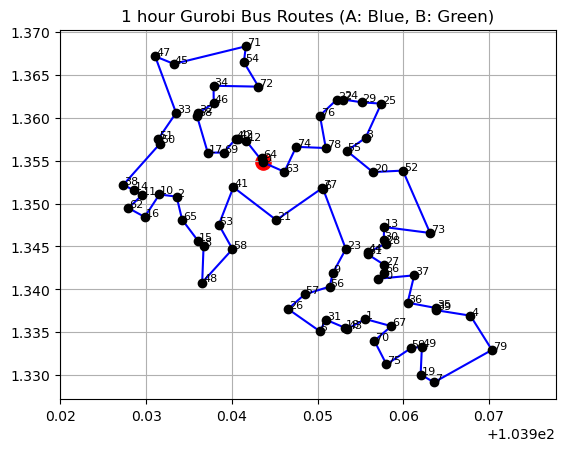

In [21]:
def connectpoints(x, y, p1, p2, color):
    plt.plot([x[p1], x[p2]], [y[p1], y[p2]], color=color)

# Get selected arcs
linkA = [(i, j) for i in range(n) for j in range(n) if i != j and A[i, j].X > 0.5]
linkB = [(i, j) for i in range(n) for j in range(n) if i != j and B[i, j].X > 0.5]

# Plot routes
for i, j in linkA: connectpoints(coord_x, coord_y, i, j, 'blue')
for i, j in linkB: connectpoints(coord_x, coord_y, i, j, 'green')

# Plot cities and depot
plt.plot(coord_x, coord_y, 'ko')  # cities
plt.scatter(coord_x[s], coord_y[s], color='red', s=120)

# Label nodes
for idx, (x, y) in enumerate(zip(coord_x, coord_y)):
    plt.text(x + 0.0001, y + 0.0001, str(idx), fontsize=8)

plt.title("1 hour Gurobi Bus Routes (A: Blue, B: Green)")
plt.axis('equal')
plt.grid(True)
plt.show()


In [19]:
model.ObjVal

0.23979997996077443

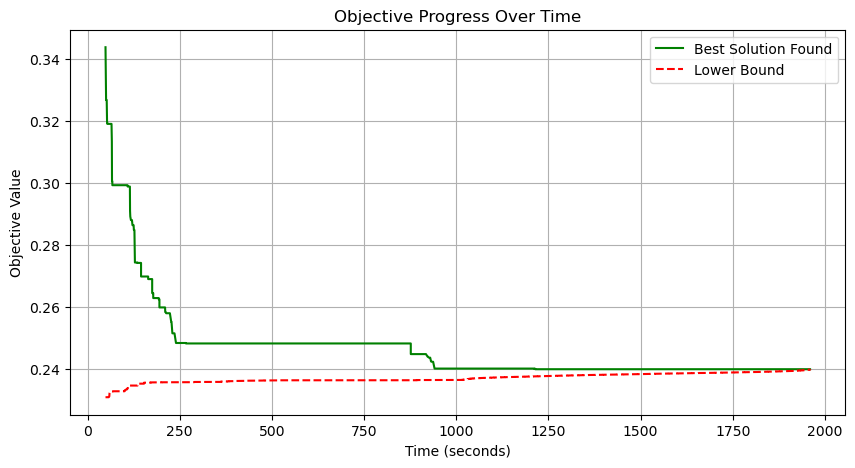

In [20]:
# Plot the graph using the information gathered in the callback
plt.figure(figsize=(10, 5))
plt.plot(times, obj_vals, label="Best Solution Found", color='green')
plt.plot(times, bounds, label="Lower Bound", color='red', linestyle='--')
plt.xlabel("Time (seconds)")
plt.ylabel("Objective Value")
plt.title("Objective Progress Over Time")
plt.legend()
plt.grid(True)
plt.show()